<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/models/3-classes/knee_oa_xception_(N%20Mohammed).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Knee Osteoarthritis Severity Classification with Xception
Three-class classification: Grade 2 / Grade 3 / Grade 4




## 1. Install Dependencies

In [1]:
!pip install -q kagglehub timm

## 2. Imports

In [2]:
import kagglehub
import os
import time
import cv2
import numpy as np
from PIL import Image
from collections import Counter
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torch.backends.cudnn as cudnn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, datasets
import timm
from sklearn.metrics import (
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    cohen_kappa_score
)

## 3. Download Dataset from Kaggle

In [3]:
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)

100%|██████████| 204M/204M [00:02<00:00, 78.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1


## 4. Pre-processing & Data Augmentation

In [4]:
base = path

# 1) Denoising & Contrast Enhancement (Gaussian Blur + CLAHE)
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))                                    # Convert to grayscale
        g = cv2.GaussianBlur(g, (3, 3), 0)                                # Noise reduction
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)  # Enhance local contrast
        return Image.fromarray(g)

# 2) Validation & Test pipeline (No augmentation)
tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3) Training pipeline (Enhanced augmentation to prevent overfitting)
train_tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),                                          # Anatomically valid flip for knee X-rays
    transforms.RandomRotation(15),                                                   # Slight rotation
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),  # Slight shift and zoom
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

## 5. Load Full Dataset

In [5]:
train_full = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val_full   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test_full  = datasets.ImageFolder(f"{base}/test",  transform=tf)

print("Full dataset -> train:", len(train_full), "| val:", len(val_full), "| test:", len(test_full))
print("Original classes:", train_full.classes)

Full dataset -> train: 5778 | val: 826 | test: 1656
Original classes: ['0', '1', '2', '3', '4']


## 6. Filter Classes (Grades 2, 3, 4 Only)

In [6]:
class_names = ["Grade 2", "Grade 3", "Grade 4"]

class Keep234(Dataset):
    def __init__(self, ds):
        self.ds = ds
        self.idx = [i for i, t in enumerate(ds.targets) if t >= 2]   # Keep grades 2, 3, 4 only
        self.targets = [ds.targets[i] - 2 for i in self.idx]         # Remap 2, 3, 4 -> 0, 1, 2
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        x, _ = self.ds[self.idx[i]]
        return x, self.targets[i]

train = Keep234(train_full)
val   = Keep234(val_full)
test  = Keep234(test_full)

splits = [("train", train), ("val", val), ("test", test)]
total_samples = sum(len(ds) for _, ds in splits)

for name, ds in splits:
    split_size = len(ds)
    split_pct = (split_size / total_samples) * 100
    counts = Counter(ds.targets)
    class_dist = {class_names[k]: f"{v} ({v/split_size*100:.1f}%)" for k, v in sorted(counts.items())}
    print(f"{name:5} | Total: {split_size:4} ({split_pct:.2f}%) | Classes: {class_dist}")

train | Total: 2446 (69.65%) | Classes: {'Grade 2': '1516 (62.0%)', 'Grade 3': '757 (30.9%)', 'Grade 4': '173 (7.1%)'}
val   | Total:  345 (9.82%) | Classes: {'Grade 2': '212 (61.4%)', 'Grade 3': '106 (30.7%)', 'Grade 4': '27 (7.8%)'}
test  | Total:  721 (20.53%) | Classes: {'Grade 2': '447 (62.0%)', 'Grade 3': '223 (30.9%)', 'Grade 4': '51 (7.1%)'}


## 7. Class Weights & DataLoaders

In [7]:
# Compute class weights to handle class imbalance
counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (3 * counts[i]) for i in range(3)]
class_weights = torch.tensor(weights, dtype=torch.float)
print("Class weights:", [round(w, 2) for w in weights])

# Create DataLoaders
train_loader = DataLoader(train, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

Class weights: [0.54, 1.08, 4.71]


## 8. Visualize Pre-processed Samples

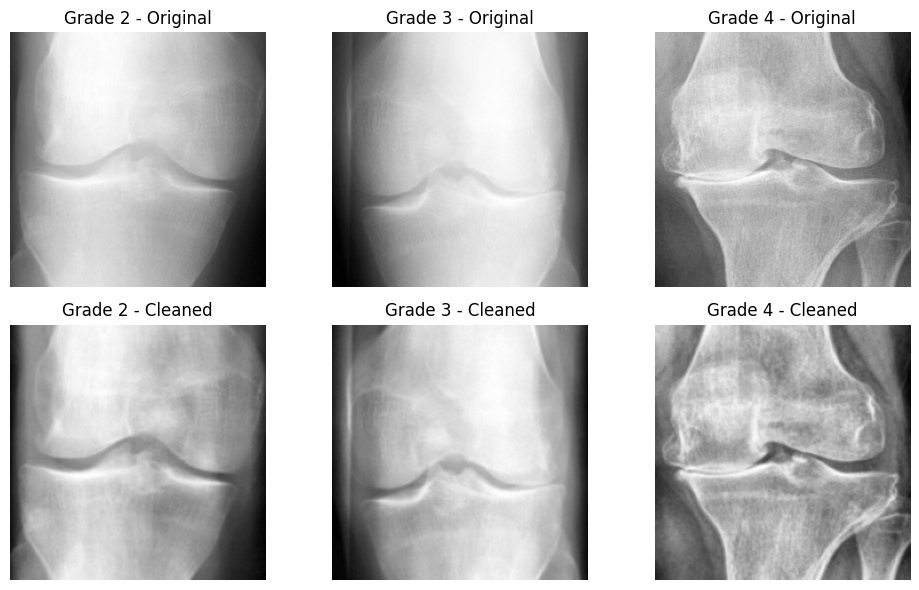

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for j, k in enumerate([2, 3, 4]):
    path_k = train_full.samples[train_full.targets.index(k)][0]
    original = Image.open(path_k).convert("L")
    cleaned = Denoise()(original)
    axes[0][j].imshow(original, cmap="gray")
    axes[0][j].set_title(f"Grade {k} - Original")
    axes[0][j].axis("off")
    axes[1][j].imshow(cleaned, cmap="gray")
    axes[1][j].set_title(f"Grade {k} - Cleaned")
    axes[1][j].axis("off")
plt.tight_layout()
plt.show()

## 9. Device Configuration & Helper Functions

In [9]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
cudnn.benchmark = True
print("Using device:", device)

def accuracy_fn(y_true, y_pred):
    """Calculates accuracy between truth labels and predictions (in %)."""
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

def train_step(model, data_loader, loss_fn, optim, acc_fn, device=device):
    train_loss, train_acc = 0.0, 0.0
    model.to(device)
    model.train()  # Set model to training mode

    for input, label in data_loader:
        input, label = input.to(device), label.to(device)

        # 1. Forward pass
        output = model(input)

        # 2. Calculate loss and accuracy
        loss = loss_fn(output, label)
        train_loss += loss.item()
        train_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

        # 3. Optimizer zero grad
        optim.zero_grad()

        # 4. Backward pass
        loss.backward()

        # 5. Optimizer step
        optim.step()

    train_loss /= len(data_loader)
    train_acc /= len(data_loader)
    print(f'Train loss: {train_loss:.4f}, Train acc: {train_acc:.2f}%')

def test_step(model, data_loader, loss_fn, acc_fn, tag='Val', device=device):
    test_loss, test_acc = 0.0, 0.0
    all_preds, all_labels = [], []
    model.to(device)
    model.eval()  # Set model to evaluation mode

    with torch.inference_mode():
        for input, label in data_loader:
            input, label = input.to(device), label.to(device)

            # 1. Forward pass
            output = model(input)
            pred = output.argmax(dim=1)

            # 2. Calculate loss and accuracy
            loss = loss_fn(output, label)
            test_loss += loss.item()
            test_acc += acc_fn(y_true=label, y_pred=pred)

            all_preds.extend(pred.cpu().numpy())
            all_labels.extend(label.cpu().numpy())

    test_loss /= len(data_loader)
    test_acc /= len(data_loader)
    macro_f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    print(f'{tag} loss: {test_loss:.4f}, {tag} acc: {test_acc:.2f}%, {tag} macro-F1: {macro_f1:.4f}')
    return test_acc, macro_f1

Using device: cuda


## 10. Initialize Model (Xception), Loss, Optimizer & Scheduler

In [10]:
# Load pre-trained Xception with drop_rate=0.5 for stronger regularization against overfitting
try:
    model_ft = timm.create_model("legacy_xception", pretrained=True, num_classes=3, drop_rate=0.5)
except Exception as e:
    print("legacy_xception failed, trying 'xception':", e)
    model_ft = timm.create_model("xception", pretrained=True, num_classes=3, drop_rate=0.5)

model_ft = model_ft.to(device)

# CrossEntropyLoss with class weights and label smoothing (0.1) to prevent overconfidence
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device), label_smoothing=0.1)

# AdamW optimizer with weight decay (L2 regularization) to penalize large weights
optimizer = optim.AdamW(model_ft.parameters(), lr=0.0001, weight_decay=0.01)

# Cosine Annealing scheduler to smoothly decay the learning rate after each epoch
epochs = 25
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

acc_fn = accuracy_fn

Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth


## 11. Training & Validation Loop

In [11]:
since = time.time()
best_model_params_path = 'xception_3class_best.pt'
torch.save(model_ft.state_dict(), best_model_params_path)

best_f1 = 0.0

for epoch in tqdm(range(epochs)):
    print(f'\nEpoch: {epoch + 1} / {epochs}')
    print('-' * 20)

    train_step(
        model=model_ft,
        data_loader=train_loader,
        loss_fn=loss_fn,
        optim=optimizer,
        acc_fn=acc_fn
    )

    val_acc, val_f1 = test_step(
        model=model_ft,
        data_loader=val_loader,
        loss_fn=loss_fn,
        acc_fn=acc_fn,
        tag='Val'
    )

    # Step the scheduler at the end of each epoch
    scheduler.step()

    # Save best model based on Validation Macro-F1
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model_ft.state_dict(), best_model_params_path)
        print(f'--> Best model saved with Val Macro-F1: {best_f1:.4f}')

time_elapsed = time.time() - since
print(f'\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
print(f'Best Val Macro-F1: {best_f1:.4f}')

  0%|          | 0/25 [00:00<?, ?it/s]


Epoch: 1 / 25
--------------------
Train loss: 1.1205, Train acc: 42.37%
Val loss: 1.1614, Val acc: 66.89%, Val macro-F1: 0.5752
--> Best model saved with Val Macro-F1: 0.5752

Epoch: 2 / 25
--------------------
Train loss: 0.8979, Train acc: 71.71%
Val loss: 1.0533, Val acc: 80.24%, Val macro-F1: 0.7439
--> Best model saved with Val Macro-F1: 0.7439

Epoch: 3 / 25
--------------------
Train loss: 0.8056, Train acc: 79.78%
Val loss: 1.0097, Val acc: 81.45%, Val macro-F1: 0.8077
--> Best model saved with Val Macro-F1: 0.8077

Epoch: 4 / 25
--------------------
Train loss: 0.7798, Train acc: 82.38%
Val loss: 0.9807, Val acc: 85.07%, Val macro-F1: 0.8232
--> Best model saved with Val Macro-F1: 0.8232

Epoch: 5 / 25
--------------------
Train loss: 0.7507, Train acc: 85.88%
Val loss: 0.9892, Val acc: 81.66%, Val macro-F1: 0.7782

Epoch: 6 / 25
--------------------
Train loss: 0.7047, Train acc: 86.38%
Val loss: 0.9528, Val acc: 89.05%, Val macro-F1: 0.8743
--> Best model saved with Val Ma

## 12. Load Best Model & Evaluate on Test Set


In [16]:
# Load the best model weights for final testing
model_ft.load_state_dict(torch.load(best_model_params_path, map_location=device, weights_only=True))

print("\n===== Final Test Set Evaluation =====")
test_step(
    model=model_ft,
    data_loader=test_loader,
    loss_fn=loss_fn,
    acc_fn=acc_fn,
    tag='Test'
)


===== Final Test Set Evaluation =====
Test loss: 0.9877, Test acc: 84.97%, Test macro-F1: 0.8300


(84.96643222506394, 0.8299909362907147)

## 13. Additional Metrics (Balanced Accuracy / QWK / Classification Report)

In [17]:
model_ft.eval()
all_preds = []
all_labels = []

with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model_ft(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

qwk = cohen_kappa_score(all_labels, all_preds, labels=[0, 1, 2], weights="quadratic")
bal_acc = balanced_accuracy_score(all_labels, all_preds) * 100

print(f"\nBalanced Accuracy: {bal_acc:.2f}%")
print(f"Quadratic Weighted Kappa (QWK): {qwk:.4f}\n")

print("Classification Report (Test Set):")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(3)),
    target_names=class_names,
    zero_division=0,
    digits=3
))


Balanced Accuracy: 84.39%
Quadratic Weighted Kappa (QWK): 0.8001

Classification Report (Test Set):
              precision    recall  f1-score   support

     Grade 2      0.928     0.864     0.895       447
     Grade 3      0.733     0.825     0.776       223
     Grade 4      0.796     0.843     0.819        51

    accuracy                          0.850       721
   macro avg      0.819     0.844     0.830       721
weighted avg      0.858     0.850     0.853       721



## 14. Confusion Matrix

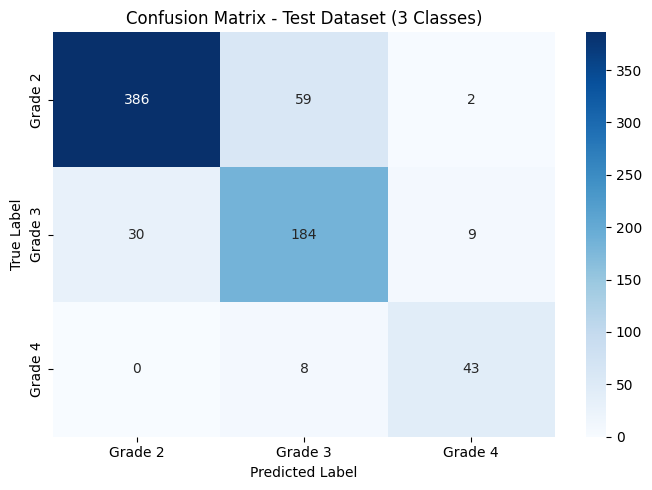

In [14]:
cm = confusion_matrix(all_labels, all_preds, labels=list(range(3)))
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Test Dataset (3 Classes)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()